# ML-10 — Content Action Playbook

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [3]:
!ls -la /content

total 16
drwxr-xr-x 1 root root 4096 Sep 16 13:26 .
drwxr-xr-x 1 root root 4096 Sep 29 16:43 ..
drwxr-xr-x 4 root root 4096 Sep 16 13:26 .config
drwxr-xr-x 1 root root 4096 Sep 16 13:26 sample_data


In [4]:
%cd /content
!git clone https://github.com/Dev-hashh/flyrank-ml-internship-starter
%cd /content/flyrank-ml-internship-starter


/content
Cloning into 'flyrank-ml-internship-starter'...
remote: Enumerating objects: 185, done.
remote: Counting objects: 100% (185/185), done.
remote: Compressing objects: 100% (154/154), done.
remote: Total 185 (delta 86), reused 84 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (185/185), 1.98 MiB | 13.58 MiB/s, done.
Resolving deltas: 100% (86/86), done.
/content/flyrank-ml-internship-starter


In [5]:
!pwd
!ls

/content/flyrank-ml-internship-starter
AGENTS.md  DATA_USE.md	LICENSE    README.md	     SETUP.md	 work
CLAUDE.md  docs		notebooks  requirements.txt  skills
data	   GUIDE.md	outputs    scripts	     submission


In [6]:
!python3 -m pip install reportlab
!python scripts/run_all.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 23.6 MB/s eta 0:00:00

▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label
Prepared 30,000 rows from 30,000 raw rows
Wrote /content/flyrank-ml-internship-starter/data/processed/refresh_feature_vector.csv

▶ Step 2/5 — Baseline — a transparent hand-written rule to beat
Wrote baseline queue: /content/flyrank-ml-internship-starter/data/processed/baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340

▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)
Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: /content/flyrank-ml-internship-starter/data/processed/model_predictions.csv
Wrote model results: /content/flyrank-ml-internship-starter/outputs/model_results.json

▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report
Wrote fi

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the model predictions generated by the previous ML stages.
# Adjust the path only if your repository structure is different.
pred_path = Path("/content/flyrank-ml-internship-starter/outputs/refresh_queue.csv")

queue = pd.read_csv(pred_path)

print("Shape:", queue.shape)
print("Columns:")
print(queue.columns.tolist())

queue.head()

Shape: (30000, 28)
Columns:
['final_rank', 'content_id', 'client_id', 'final_refresh_score', 'best_model_name', 'best_model_probability', 'baseline_refresh_score', 'confidence', 'suggested_action', 'final_reason_codes', 'is_declining_label', 'impressions_90d', 'clicks_90d', 'sessions_90d', 'avg_position', 'ctr', 'content_age_days', 'days_since_last_update', 'word_count', 'trend_direction', 'competition_level', 'content_type', 'main_intent', 'age_tier', 'freshness_tier', 'word_count_tier', 'impression_tier', 'position_tier']


,final_rank,content_id,client_id,final_refresh_score,best_model_name,best_model_probability,baseline_refresh_score,confidence,suggested_action,final_reason_codes,...,word_count,trend_direction,competition_level,content_type,main_intent,age_tier,freshness_tier,word_count_tier,impression_tier,position_tier
0,1,content_1f080331fa2b,client_3fdba35f04,81.734212,random_forest,0.783472,0.844481,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|low...,...,1404.0,down,MEDIUM,keyword article,informational,91-180,91-180,1000-2000,good,page_1
1,2,content_d6570c51c9bd,client_3fdba35f04,81.603243,random_forest,0.849842,0.695884,medium,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,...,1362.0,down,MEDIUM,keyword article,informational,91-180,91-180,1000-2000,moderate,striking
2,3,content_6aa43079fb0c,client_3fdba35f04,81.544618,random_forest,0.789490,0.825477,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,...,1457.0,down,LOW,keyword article,informational,91-180,91-180,1000-2000,good,page_1
3,4,content_72e800a9c214,client_3fdba35f04,81.169731,random_forest,0.776297,0.842545,high,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,...,1371.0,down,MEDIUM,keyword article,commercial,91-180,91-180,1000-2000,good,page_1
4,5,content_e04eb9549989,client_3fdba35f04,80.957565,random_forest,0.816010,0.749468,medium,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,...,1408.0,down,LOW,keyword article,informational,91-180,91-180,1000-2000,good,page_1


In [8]:
# ============================================================
# ML-10: Ranked Actions + Reason Codes
# ============================================================

# Keep only the information needed by a human reviewer.
action_queue = queue[
    [
        "final_rank",
        "content_id",
        "client_id",
        "final_refresh_score",
        "best_model_name",
        "best_model_probability",
        "baseline_refresh_score",
        "confidence",
        "suggested_action",
        "final_reason_codes",
        "impressions_90d",
        "clicks_90d",
        "sessions_90d",
        "avg_position",
        "ctr",
        "content_age_days",
        "days_since_last_update",
        "word_count",
    ]
].copy()


# ------------------------------------------------------------
# Convert machine-readable reason codes into human-readable
# explanations.
# ------------------------------------------------------------

reason_explanations = {
    "model_decline_risk":
        "Model identifies elevated probability of decline.",

    "visible_model_opportunity":
        "Page has enough search visibility to justify review.",

    "ctr_review_candidate":
        "CTR suggests the page may warrant title/snippet review.",

    "engagement_review_candidate":
        "Engagement signals suggest the page warrants review.",

    "freshness_review_candidate":
        "Page has a relatively long time since its last update.",

    "low_evidence_monitor":
        "Available evidence is limited, so monitor before taking action."
}


def explain_reasons(reason_string):
    """Return readable explanations for supported reason codes."""

    if pd.isna(reason_string):
        return []

    codes = str(reason_string).split("|")

    explanations = []

    for code in codes:
        if code in reason_explanations:
            explanations.append(reason_explanations[code])

    return explanations


# Create a new explanation column.
action_queue["reason_explanations"] = (
    action_queue["final_reason_codes"]
    .apply(explain_reasons)
)


# ------------------------------------------------------------
# Ensure queue is sorted by the validated final ranking.
# ------------------------------------------------------------

action_queue = action_queue.sort_values(
    "final_rank",
    ascending=True
).reset_index(drop=True)


# ------------------------------------------------------------
# Display the first 20 pages for human review.
# ------------------------------------------------------------

display(
    action_queue[
        [
            "final_rank",
            "content_id",
            "final_refresh_score",
            "confidence",
            "suggested_action",
            "reason_explanations"
        ]
    ].head(20)
)

,final_rank,content_id,final_refresh_score,confidence,suggested_action,reason_explanations
0,1,content_1f080331fa2b,81.734212,high,refresh_and_review_ctr,[Model identifies elevated probability of decl...
1,2,content_d6570c51c9bd,81.603243,medium,refresh_and_review_ctr,[Model identifies elevated probability of decl...
2,3,content_6aa43079fb0c,81.544618,high,refresh_and_review_ctr,[Model identifies elevated probability of decl...
3,4,content_72e800a9c214,81.169731,high,refresh_and_review_ctr,[Model identifies elevated probability of decl...
4,5,content_e04eb9549989,80.957565,medium,refresh_and_review_ctr,[Model identifies elevated probability of decl...
5,6,content_b69288c5e701,80.798090,high,refresh_and_review_ctr,[Model identifies elevated probability of decl...
6,7,content_9b6df29f7889,80.650656,high,refresh_and_review_ctr,[Model identifies elevated probability of decl...
7,8,content_ba6f9dfcbca1,80.432641,medium,refresh,[Model identifies elevated probability of decl...
8,9,content_4d76cdb3387b,80.428403,medium,refresh_and_review_ctr,[Model identifies elevated probability of decl...
9,10,content_b4f35d640b1c,80.428243,medium,refresh,[Model identifies elevated probability of decl...


In [9]:
# ============================================================
# Action → Reason-Code Mapping
# ============================================================

action_playbook = {
    "refresh_and_review_ctr": {
        "description": (
            "Review the page for content freshness and inspect "
            "title/snippet performance before making changes."
        ),
        "review_checks": [
            "Confirm that the content is still accurate and relevant.",
            "Check whether the title and snippet accurately represent the page.",
            "Review CTR relative to the page's search visibility.",
            "Check whether the observed decline is persistent rather than temporary."
        ]
    },

    "refresh_and_review_engagement": {
        "description": (
            "Review the content for freshness, usefulness, and "
            "possible engagement issues."
        ),
        "review_checks": [
            "Confirm that the content satisfies the intended search need.",
            "Check whether important information is missing or outdated.",
            "Review engagement signals alongside search visibility.",
            "Avoid adding content solely to increase word count."
        ]
    },

    "monitor": {
        "description": (
            "Monitor the page rather than immediately recommending "
            "a content change because the available evidence is limited."
        ),
        "review_checks": [
            "Check whether additional observations are needed.",
            "Review traffic and visibility trends over time.",
            "Reassess if stronger evidence of an opportunity appears."
        ]
    }
}


def get_action_description(action):
    """Return the human-readable description for an action."""
    return action_playbook.get(
        action,
        {
            "description": "Human review required before selecting an action."
        }
    )["description"]


def get_review_checks(action):
    """Return the human-review checklist for an action."""
    return action_playbook.get(
        action,
        {
            "review_checks": [
                "Review the available evidence before taking action."
            ]
        }
    )["review_checks"]


action_queue["action_description"] = (
    action_queue["suggested_action"]
    .apply(get_action_description)
)

action_queue["review_checks"] = (
    action_queue["suggested_action"]
    .apply(get_review_checks)
)


# Display the action distribution.
action_summary = (
    action_queue["suggested_action"]
    .value_counts()
    .rename_axis("suggested_action")
    .reset_index(name="page_count")
)

display(action_summary)

,suggested_action,page_count
0,monitor,13083
1,refresh,8188
2,refresh_and_review_ctr,6654
3,refresh_and_review_engagement,1993
4,expand_and_refresh,82


### How to interpret the ranked queue

The queue is a prioritization aid for human SEO review. A higher `final_rank`
indicates that the page received a higher validated refresh-priority score.

The `suggested_action` and reason codes translate the model output into a
review workflow. They do not represent automatic instructions to change,
delete, merge, or publish content.

Reason codes are intended to make the ranking auditable by showing which
observable signals contributed to the recommended review path.

### Action distribution

The ranked queue contains 30,000 pages. The largest action group is `monitor`
(13,083 pages; 43.61%), followed by `refresh` (8,188; 27.29%) and
`refresh_and_review_ctr` (6,654; 22.18%).

Only 82 pages (0.27%) are assigned to `expand_and_refresh`. This distribution
shows that the playbook is being used primarily to prioritize review rather
than automatically recommend a content change for every page.

The action labels are decision-support categories. They should be reviewed
against the page's underlying evidence before any content change is made.

In [10]:
# ============================================================
# Archetype → Action Mapping
# ============================================================

archetype_action_mapping = pd.DataFrame([
    {
        "archetype": "Declining + visible",
        "recommended_action": "refresh",
        "human_review": "Check whether the decline is persistent and whether the content is outdated."
    },
    {
        "archetype": "Declining + visible + CTR concern",
        "recommended_action": "refresh_and_review_ctr",
        "human_review": "Review content freshness and inspect title/snippet alignment with search intent."
    },
    {
        "archetype": "Declining + engagement concern",
        "recommended_action": "refresh_and_review_engagement",
        "human_review": "Check content usefulness, relevance, completeness, and engagement signals."
    },
    {
        "archetype": "Strong visibility but insufficient evidence",
        "recommended_action": "monitor",
        "human_review": "Collect more evidence before recommending a substantive content change."
    },
    {
        "archetype": "Potential content-depth opportunity",
        "recommended_action": "expand_and_refresh",
        "human_review": "Confirm that additional useful coverage is actually missing; do not add filler."
    }
])

display(archetype_action_mapping)

,archetype,recommended_action,human_review
0,Declining + visible,refresh,Check whether the decline is persistent and wh...
1,Declining + visible + CTR concern,refresh_and_review_ctr,Review content freshness and inspect title/sni...
2,Declining + engagement concern,refresh_and_review_engagement,"Check content usefulness, relevance, completen..."
3,Strong visibility but insufficient evidence,monitor,Collect more evidence before recommending a su...
4,Potential content-depth opportunity,expand_and_refresh,Confirm that additional useful coverage is act...


### Archetype-to-action policy

The mapping translates recurring evidence patterns into practical review
paths. It is a policy layer around the ranked output rather than a new
machine-learning model.

The mapping does not imply that the recommended action will improve traffic,
rankings, CTR, or engagement. A reviewer must confirm that the underlying
content and search context support the action.


### Decay / refresh insight

The queue is designed around the idea that pages showing declining performance
may deserve earlier review, particularly when they still have meaningful
search visibility.

However, decline alone is not evidence that a content refresh will cause
recovery. A reviewer should distinguish persistent deterioration from
temporary variation, seasonality, changes in search demand, technical issues,
or other explanations.

Content age and time since the last update can therefore be treated as
review context rather than as proof that a page needs refreshing.


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### Intended use

This playbook is intended for SEO specialists and content editors who need to
prioritize which pages should be reviewed first for a possible content action.

The output combines the validated refresh-priority score with suggested actions,
reason codes, and confidence labels. It is designed to reduce the amount of
manual screening required when reviewing a large content inventory.

The primary use is prioritization:

1. Identify pages near the top of the review queue.
2. Inspect the reason codes and supporting observable signals.
3. Apply the appropriate human-review checklist.
4. Decide whether to refresh, expand, investigate, or monitor the page.
5. Measure the page again after any approved change.

The queue is therefore a decision-support tool rather than an automatic
content-management system.

### What the score means

The final refresh score should be interpreted as a prioritization score.

A higher score means that the page is ranked earlier for human review based on
the validated model output and baseline signal.

It does not mean that:

- the page is guaranteed to decline;
- refreshing the page will recover traffic;
- rankings will improve after a refresh;
- CTR or engagement will increase;
- the page has a guaranteed business opportunity.

The model supports directional prioritization, not causal attribution or
guaranteed outcomes.

### Where the playbook is valid

The playbook is most appropriate when:

- the page has observable search-performance evidence;
- the required input signals are available;
- the page belongs to a content inventory similar to the data used during
  validation;
- the reviewer can inspect the underlying page and search context;
- the model is being used to prioritize review rather than make an automatic
  content decision.

The validation included client-group holdout evaluation, so the ranking should
still be treated as evidence from the evaluated dataset rather than a guarantee
of performance for every future client or content type.

### Important limitations

Several limitations should be considered when interpreting the queue.

**Low-volume pages:** Small numbers of impressions, clicks, or sessions can
produce noisy measurements. These pages should generally receive more cautious
interpretation.

**CTR interpretation:** CTR should not be interpreted independently of search
position and visibility. A low CTR by itself does not prove that a title or
meta description is poor.

**Observational data:** The model uses observed search, content, and engagement
signals. These relationships do not establish that a recommended content
change will cause a future improvement.

**Changing search conditions:** Search demand, rankings, competitors, and
seasonality can change after the features used by the model were collected.

**Generalization:** Performance on the validation population does not guarantee
the same performance on every future client, page type, or dataset.

**Human context:** The model cannot inspect the full editorial or business
context of a page. Human review is required before taking action.

### Intended workflow

The recommended workflow is:

**Model ranking → human evidence review → content decision → approved action
→ follow-up measurement**

The model should not directly publish, delete, merge, or rewrite content.

After a refresh, the result should be evaluated using a defined follow-up
window rather than treating the immediate post-change result as proof of
causality. The FlyRank content-refresh playbook uses 30-, 60-, and 90-day
follow-up checks as examples of this measurement approach.

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human review is required before action

The ranked queue is a prioritization tool. A human reviewer must inspect the
page and its supporting evidence before approving any content action.

For each queued page, the reviewer should check:

1. **Performance evidence**
   - Are impressions, clicks, sessions, CTR, and position sufficient to
     support the recommendation?
   - Is the observed movement persistent rather than a short-term fluctuation?

2. **Search context**
   - Is the page still relevant to the search demand it serves?
   - Is the page's average position appropriate for interpreting its CTR?
   - Could a SERP change explain the movement instead of a content problem?

3. **Content quality and freshness**
   - Are statistics, dates, examples, references, and links still current?
   - Are important sections missing?
   - Is the page genuinely outdated or incomplete?

4. **Alternative explanations**
   - Could seasonality explain the decline?
   - Could another page on the same site have absorbed the demand?
   - Could low volume or measurement noise explain the movement?

5. **Action suitability**
   - Is there a specific improvement that can realistically be made?
   - Would refreshing, expanding, or reviewing the page address the observed
     issue?
   - Would leaving the page unchanged and monitoring it be more appropriate?

The reviewer should record the final decision rather than treating the model's
suggested action as an instruction.

In [11]:
# ============================================================
# Human Review Checklist by Suggested Action
# ============================================================

human_review_rules = {
    "refresh": [
        "Confirm the decline is persistent.",
        "Check whether the page contains outdated information.",
        "Check whether the page still matches its search intent.",
        "Rule out seasonality, consolidation, and low-volume noise.",
        "Identify a specific content improvement before approving a refresh."
    ],

    "refresh_and_review_ctr": [
        "Confirm the page has meaningful search visibility.",
        "Interpret CTR relative to average position.",
        "Check whether the title/snippet accurately represents the page.",
        "Rule out SERP changes or other reasons for click loss.",
        "Do not assume low CTR alone means the title or description is poor."
    ],

    "refresh_and_review_engagement": [
        "Check whether the content satisfies the intended search need.",
        "Review the page structure and readability.",
        "Look for missing explanations, examples, or useful sections.",
        "Check engagement signals alongside search visibility.",
        "Do not add content merely to increase word count."
    ],

    "expand_and_refresh": [
        "Confirm that meaningful topical coverage is missing.",
        "Identify specific sections that would improve usefulness.",
        "Check that the page already has sufficient visibility to justify the work.",
        "Avoid adding filler or unnecessary text."
    ],

    "monitor": [
        "Check whether the available evidence is sufficient for intervention.",
        "Review the page again after additional observations are available.",
        "Monitor visibility, clicks, CTR, and position for persistent movement."
    ]
}


def get_human_review_rules(action):
    return human_review_rules.get(
        action,
        ["Review the page and supporting evidence before taking action."]
    )


action_queue["human_review_rules"] = (
    action_queue["suggested_action"]
    .apply(get_human_review_rules)
)

display(
    action_queue[
        [
            "final_rank",
            "content_id",
            "suggested_action",
            "confidence",
            "human_review_rules"
        ]
    ].head(10)
)

,final_rank,content_id,suggested_action,confidence,human_review_rules
0,1,content_1f080331fa2b,refresh_and_review_ctr,high,[Confirm the page has meaningful search visibi...
1,2,content_d6570c51c9bd,refresh_and_review_ctr,medium,[Confirm the page has meaningful search visibi...
2,3,content_6aa43079fb0c,refresh_and_review_ctr,high,[Confirm the page has meaningful search visibi...
3,4,content_72e800a9c214,refresh_and_review_ctr,high,[Confirm the page has meaningful search visibi...
4,5,content_e04eb9549989,refresh_and_review_ctr,medium,[Confirm the page has meaningful search visibi...
5,6,content_b69288c5e701,refresh_and_review_ctr,high,[Confirm the page has meaningful search visibi...
6,7,content_9b6df29f7889,refresh_and_review_ctr,high,[Confirm the page has meaningful search visibi...
7,8,content_ba6f9dfcbca1,refresh,medium,"[Confirm the decline is persistent., Check whe..."
8,9,content_4d76cdb3387b,refresh_and_review_ctr,medium,[Confirm the page has meaningful search visibi...
9,10,content_b4f35d640b1c,refresh,medium,"[Confirm the decline is persistent., Check whe..."


### No-go list: decisions that should not be automated

The following decisions remain outside the scope of the model:

- Automatically publishing rewritten or expanded content.
- Automatically deleting or pruning a page.
- Automatically merging or redirecting pages.
- Automatically changing titles, descriptions, or other metadata.
- Automatically declaring a page "bad" because it has a high priority score.
- Automatically claiming that a refresh caused traffic or ranking recovery.
- Automatically escalating a page to a business-critical action without review.
- Automatically overriding editorial, legal, brand, or subject-matter review.
- Automatically using the queue to make decisions when required input signals
  are missing or unreliable.

The model may prioritize pages for investigation, but the final content
decision belongs to a human reviewer.

### Why human review cannot be removed

The model operates on observable search, content, and engagement signals. It
does not observe the complete editorial, business, technical, or competitive
context of a page.

A high score therefore means:

> "Review this page earlier."

It does not mean:

> "Make this change automatically."

In particular, the available observational data cannot establish that a
specific refresh caused a subsequent recovery. Any claim of causal impact
would require an appropriate experiment or causal design.

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### Monitoring framework

The playbook should be monitored at three levels:

1. **Input/data quality** — whether the signals used by the ranking remain
   available and plausible.
2. **Recommendation stability** — whether the distribution of scores, actions,
   confidence labels, and reason codes changes substantially.
3. **Model performance** — whether new labeled data shows deterioration in
   ranking quality.

These checks are monitoring policies for future use. They were not themselves
validated as production thresholds in this research project.

In [12]:
# ============================================================
# Monitoring Snapshot
# ============================================================

monitoring_summary = {
    "total_pages": len(action_queue),

    "missing_values": int(
        action_queue.isna().sum().sum()
    ),

    "high_confidence_share": float(
        (action_queue["confidence"] == "high").mean()
    ),

    "medium_confidence_share": float(
        (action_queue["confidence"] == "medium").mean()
    ),

    "low_confidence_share": float(
        (action_queue["confidence"] == "low").mean()
    ),

    "mean_priority_score": float(
        action_queue["final_refresh_score"].mean()
    ),

    "median_priority_score": float(
        action_queue["final_refresh_score"].median()
    ),
}

monitoring_snapshot = pd.DataFrame(
    monitoring_summary.items(),
    columns=["metric", "value"]
)

display(monitoring_snapshot)

,metric,value
0,total_pages,30000.000000
1,missing_values,0.000000
2,high_confidence_share,0.120067
3,medium_confidence_share,0.379933
4,low_confidence_share,0.500000
5,mean_priority_score,49.799459
6,median_priority_score,53.607493


In [13]:
# ============================================================
# Action Distribution Monitoring
# ============================================================

action_monitoring = (
    action_queue["suggested_action"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("share_percent")
    .reset_index()
    .rename(columns={"index": "suggested_action"})
)

display(action_monitoring)

,suggested_action,share_percent
0,monitor,43.61
1,refresh,27.29
2,refresh_and_review_ctr,22.18
3,refresh_and_review_engagement,6.64
4,expand_and_refresh,0.27


### Proposed monitoring triggers

The following conditions should trigger investigation rather than automatic
retraining:

| Area | Trigger | Follow-up |
|---|---|---|
| Missing data | Required features become unavailable or missingness increases materially | Inspect the data pipeline |
| Feature drift | Input distributions change materially from the development data | Re-audit model applicability |
| Action distribution | The share of recommended actions changes substantially | Inspect score and rule behavior |
| Confidence distribution | High/medium/low confidence proportions change substantially | Review evidence thresholds |
| Reason codes | Reason-code frequencies change unexpectedly | Inspect upstream signals and policy |
| Model performance | Precision@50, ROC-AUC, or Average Precision deteriorates on newly labeled data | Re-evaluate or retrain |
| New content/client types | New populations differ substantially from the validation data | Perform additional validation |
| Human review | Reviewers identify systematic false positives or misleading recommendations | Revise policy, features, or model |

These are proposed monitoring triggers, not experimentally established
production thresholds.

### Retrain / revalidation policy

Retraining should not happen automatically simply because a scheduled date has
arrived.

A new training cycle should first be considered when monitoring indicates that
the current model may no longer represent the decision environment.

Candidate triggers include:

- measurable deterioration in ranking performance on newly labeled data;
- meaningful changes in the input feature distributions;
- systematic false positives identified during human review;
- changes in the target-label definition;
- addition of substantially different clients or content populations;
- discovery of a feature that was unavailable at decision time or otherwise
  creates leakage risk.

Before retraining, the data and label definitions should be re-audited. A new
model should then be compared with the existing model and the baseline using
the same validation design where possible.

Retraining is therefore a response to evidence of model degradation or
environmental change, rather than an automatic action.

### Trigger response

The response to a monitoring trigger is:

**Detect → investigate → revalidate → retrain only if justified → compare with
the existing model → update the playbook**

A trigger does not automatically invalidate the model. It indicates that the
current assumptions or performance should be investigated.

Until the issue is understood, recommendations should receive additional
human scrutiny rather than being automatically acted upon.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

In [14]:
# ============================================================
# ML-10: Exports for the Paper
# ============================================================

from pathlib import Path

# Repository-relative output directories
outputs_dir = Path("work/outputs")
figures_dir = Path("work/figures")

outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Outputs directory:", outputs_dir.resolve())
print("Figures directory:", figures_dir.resolve())

Outputs directory: /content/flyrank-ml-internship-starter/work/outputs
Figures directory: /content/flyrank-ml-internship-starter/work/figures


In [15]:
# ============================================================
# Export: Ranked Action Queue
# ============================================================

queue_export = action_queue.copy()

# Convert list-valued review columns to readable text for CSV export.
if "reason_explanations" in queue_export.columns:
    queue_export["reason_explanations"] = queue_export[
        "reason_explanations"
    ].apply(
        lambda x: " | ".join(x) if isinstance(x, list) else x
    )

if "human_review_rules" in queue_export.columns:
    queue_export["human_review_rules"] = queue_export[
        "human_review_rules"
    ].apply(
        lambda x: " | ".join(x) if isinstance(x, list) else x
    )

queue_path = outputs_dir / "action_queue.csv"

queue_export.to_csv(
    queue_path,
    index=False
)

print(f"Exported {len(queue_export):,} rows")
print(f"Saved to: {queue_path}")

Exported 30,000 rows
Saved to: work/outputs/action_queue.csv


In [16]:
# ============================================================
# Export: Action Summary
# ============================================================

action_summary_export = (
    action_queue["suggested_action"]
    .value_counts()
    .rename_axis("suggested_action")
    .reset_index(name="page_count")
)

action_summary_export["share_percent"] = (
    action_summary_export["page_count"]
    / action_summary_export["page_count"].sum()
    * 100
).round(2)

summary_path = outputs_dir / "action_summary.csv"

action_summary_export.to_csv(
    summary_path,
    index=False
)

display(action_summary_export)

print(f"Saved to: {summary_path}")

,suggested_action,page_count,share_percent
0,monitor,13083,43.61
1,refresh,8188,27.29
2,refresh_and_review_ctr,6654,22.18
3,refresh_and_review_engagement,1993,6.64
4,expand_and_refresh,82,0.27


Saved to: work/outputs/action_summary.csv


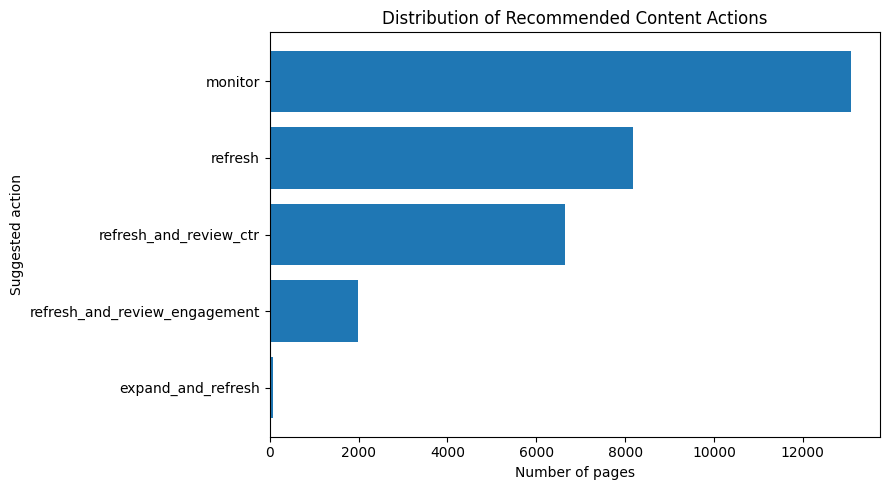

Saved to: work/figures/action_distribution.png


In [17]:
# ============================================================
# Export: Action Distribution Figure
# ============================================================

import matplotlib.pyplot as plt

plot_data = action_summary_export.sort_values(
    "page_count",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["suggested_action"],
    plot_data["page_count"]
)

plt.xlabel("Number of pages")
plt.ylabel("Suggested action")
plt.title("Distribution of Recommended Content Actions")

plt.tight_layout()

action_fig_path = figures_dir / "action_distribution.png"

plt.savefig(
    action_fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {action_fig_path}")

In [18]:
# ============================================================
# Export: Playbook Summary
# ============================================================

import json

playbook_summary = {
    "total_pages": int(len(action_queue)),
    "actions": {
        str(row["suggested_action"]): int(row["page_count"])
        for _, row in action_summary_export.iterrows()
    },
    "mean_priority_score": round(
        float(action_queue["final_refresh_score"].mean()), 4
    ),
    "median_priority_score": round(
        float(action_queue["final_refresh_score"].median()), 4
    ),
    "high_confidence_share": round(
        float(
            (action_queue["confidence"] == "high").mean()
        ),
        4
    ),
    "intended_use": (
        "Prioritize pages for human SEO review; "
        "not automatic content editing or publishing."
    ),
    "causal_claim": False
}

summary_json_path = outputs_dir / "playbook_summary.json"

with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(
        playbook_summary,
        f,
        indent=2
    )

print(f"Saved to: {summary_json_path}")

Saved to: work/outputs/playbook_summary.json


In [19]:
# ============================================================
# Verify ML-10 Exports
# ============================================================

print("Files generated for the paper:\n")

for path in [
    queue_path,
    summary_path,
    summary_json_path,
    action_fig_path
]:
    print(
        f"{'✓' if path.exists() else '✗'} "
        f"{path}"
    )

Files generated for the paper:

✓ work/outputs/action_queue.csv
✓ work/outputs/action_summary.csv
✓ work/outputs/playbook_summary.json
✓ work/figures/action_distribution.png


### Export contract

The executed notebook regenerates the files used by the research paper.

The ranked action queue is exported to `work/outputs/action_queue.csv`.
Summary statistics are exported to `work/outputs/action_summary.csv`, and
the playbook metadata is exported to `work/outputs/playbook_summary.json`.

The reusable action-distribution figure is exported to
`work/figures/action_distribution.png`.

The queue is generated by the notebook rather than treated as a manually
maintained artifact. This keeps the paper's recommendations traceable to the
executed analysis.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.